# NB1 — geometry (paper Sections 2–3a)

Computes the results of Sections 2–3a (exact coefficient loss; gradient descent, Levenberg–Marquardt, Adam). Output goes to `results/nb1/`; figures and tables are made by `figures.ipynb`.
`RUN_MODE`: `'full'` gives the paper results (about a day on a laptop CPU), `'reduced'` a subset (a few hours), `'quick'` a smoke test.
Cells 3b and 5b are diagnostics added after the audit: 3b examines the end points of the Levenberg–Marquardt failures (`lm_endpoints.csv`, `lm_endpoint_summary.csv`), 5b the relation between conditioning and outcome and the iteration budget (`g3_ordering_strict*.csv`, `kappa_init_*.csv`, `gd_budget_curve.csv`). Neither changes a primary result file.

In [1]:
# ── Cell 0: configuration ─────────────────────────────────────────────────
import time, warnings
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import jax, jax.numpy as jnp
from phaselock_core import (ARMS, Circuit, check_definition, check_gradient, random_target, XD, gd_armijo, lm_svd, adam,
                            plateau_centre, wilson, newcombe)
warnings.filterwarnings('ignore'); pd.set_option('display.width', 250); pd.set_option('display.max_columns', 40)
print('JAX', jax.__version__, jax.devices())

RUN_MODE = 'full'                                        # 'full' | 'reduced' | 'quick'
SEED = 2027
MODE = {'full':    dict(E=[8, 12, 16, 24, 32], runs=100, tune=5, gd=50000, lm=2000, ad=50000),
        'reduced': dict(E=[8, 16, 24],         runs=30,  tune=3, gd=50000, lm=2000, ad=50000),
        'quick':   dict(E=[8, 12],             runs=3,   tune=2, gd=1000,  lm=30,   ad=1000)}[RUN_MODE]
E_LIST, N_RUNS, N_TUNE = MODE['E'], MODE['runs'], MODE['tune']
GD_ITERS, LM_ITERS, AD_ITERS = MODE['gd'], MODE['lm'], MODE['ad']
FAMILIES = ['flat', 'decay']
ARM_LIST = ['serial', 'ancilla', 'parallel2']
AMP, EPS = 0.9, 1e-6                                     # a run converges if its final loss is <= EPS (1e-8 until the runs were analysed; nothing that is simulated depends on it)
AD_LRS   = [1e-3, 3e-3, 1e-2, 3e-2, 1e-1]
CHUNK    = 500 if RUN_MODE != 'quick' else 100
CK = sorted({0} | {int(v) // CHUNK * CHUNK for v in np.geomspace(CHUNK, GD_ITERS, 16)})    # kappa checkpoints
OUT = Path('results' + ('' if RUN_MODE == 'full' else f'_{RUN_MODE}')) / 'nb1'; OUT.mkdir(parents=True, exist_ok=True)
FAM_ID = {f: i for i, f in enumerate(FAMILIES)}; ARM_ID = {a: i for i, a in enumerate(ARM_LIST)}
def target_seed(fam, E, t): return SEED + 10**6 * FAM_ID[fam] + 10**4 * E + t            # t < 1000: evaluation, 5000+: tuning
def init_seed(arm, fam, E, t): return SEED + 10**8 * (ARM_ID[arm] + 1) + 10**6 * FAM_ID[fam] + 10**4 * E + t
def grid(E): return jnp.linspace(-np.pi, np.pi, 2 * E + 1, endpoint=False)
def batch(arm, fam, E, ts):
    c = Circuit(arm, E); X = grid(E); ys = [random_target(fam, E, target_seed(fam, E, t), AMP)(np.asarray(X)) for t in ts]
    Y = jnp.asarray(np.array(ys)); V = jnp.asarray([np.mean(y ** 2) - np.mean(y) ** 2 for y in ys])     # exact circle variance
    U0 = jnp.stack([c.init(init_seed(arm, fam, E, t)) for t in ts]); return c, X, Y, V, U0
print('out:', OUT.resolve(), '| checkpoints:', CK)
def todo(path, label):
    """Cells (arm, family, E) already in `path` are skipped; print both lists before anything runs."""
    done = set(map(tuple, pd.read_csv(path)[['arm', 'family', 'E']].values)) if path.exists() else set()
    want = [(a, f, E) for E in E_LIST for f in FAMILIES for a in ARM_LIST if not E % ARMS[a]['div']]
    open_ = [k for k in want if k not in done]
    print(f'{label}: {path.resolve()} ' + ('exists' if path.exists() else 'NOT FOUND') + f' | done {len(want) - len(open_)} of {len(want)} | to run: {open_}')
    return done
PG, PK, PL = OUT / 'runs_gd.csv', OUT / 'kappa.csv', OUT / 'runs_lm.csv'          # result files, defined here so that any cell can run alone
PA, PAT = OUT / 'runs_adam.csv', OUT / 'adam_tuning.csv'
for f, lab in ((PG, 'GD'), (PL, 'LM'), (PA, 'Adam')): todo(f, lab)

JAX 0.6.2 [CpuDevice(id=0)]
out: /Users/michaelpoppelaqarios/PycharmProjects/ICML_2027_phaseLocking/results/nb1 | checkpoints: [0, 500, 1000, 1500, 2000, 3000, 4000, 5500, 7500, 10500, 14500, 19500, 27000, 36500, 50000]
GD: /Users/michaelpoppelaqarios/PycharmProjects/ICML_2027_phaseLocking/results/nb1/runs_gd.csv exists | done 30 of 30 | to run: []
LM: /Users/michaelpoppelaqarios/PycharmProjects/ICML_2027_phaseLocking/results/nb1/runs_lm.csv exists | done 30 of 30 | to run: []
Adam: /Users/michaelpoppelaqarios/PycharmProjects/ICML_2027_phaseLocking/results/nb1/runs_adam.csv exists | done 30 of 30 | to run: []


In [2]:
# ── Cell 1: checks ──────────────────────────────────────────────────────────
for arm in ARM_LIST:                     # simulator = circuit definition (dense matrices, scipy), for tbl 1 and 2
    print(f'definition check {arm:9s}: {max(check_definition(arm, 8, 1), check_definition(arm, 8, 2)):.1e}')
for arm in ARM_LIST:                     # grid loss = L2 error on the circle; Lie gradient = finite difference
    c, X, Y, V, U0 = batch(arm, 'flat', 12, [0])
    Us = U0[0]; fd = np.asarray(c.jf(Us, jnp.asarray(XD))); yd = random_target('flat', 12, target_seed('flat', 12, 0), AMP)(XD)
    dense = np.mean((fd - yd) ** 2) / (np.mean(yd ** 2) - np.mean(yd) ** 2); gl = float(c.jloss(Us, X, Y[0], V[0]))
    assert abs(gl - dense) < 1e-9 * max(1, dense), (gl, dense); an, fdv = check_gradient(c, X, Y[0], V[0])
    print(f'{arm:9s}: grid loss {gl:.12f} = dense {dense:.12f} | Lie gradient {an:.8f} vs finite difference {fdv:.8f}')

definition check serial   : 6.7e-16
definition check ancilla  : 8.9e-16
definition check parallel2: 8.3e-16
serial   : grid loss 2.332823927713 = dense 2.332823927713 | Lie gradient 4.94589127 vs finite difference 4.94589127
ancilla  : grid loss 3.159690585307 = dense 3.159690585307 | Lie gradient -3.89253307 vs finite difference -3.89253308
parallel2: grid loss 1.726522952544 = dense 1.726522952544 | Lie gradient 17.84538506 vs finite difference 17.84538506


In [3]:
# ── Cell 2: gradient descent (with conditioning checkpoints) ─────────────────
PG, PK = OUT / 'runs_gd.csv', OUT / 'kappa.csv'
done = todo(PG, 'GD')
for E in E_LIST:
    for fam in FAMILIES:
        for arm in ARM_LIST:
            if (arm, fam, E) in done or E % ARMS[arm]['div']: continue
            t0 = time.time(); ts = list(range(N_RUNS)); c, X, Y, V, U0 = batch(arm, fam, E, ts)
            H, snaps = gd_armijo(c, U0, X, Y, V, GD_ITERS, CHUNK, CK)
            svals = jax.jit(jax.vmap(lambda U, y: jnp.linalg.svd(c.jac(U, X, y), compute_uv=False)))
            krow = []
            for k, S in snaps.items():
                s = np.asarray(svals(jnp.asarray(S), Y)); kap = np.log10(np.maximum(s[:, 2 * E] / s[:, 0], 1e-300))
                krow += [dict(arm=arm, family=fam, E=E, run=r, iter=k, loss=float(H[r, k]), log_kJ=float(kap[r])) for r in range(len(ts))]
            rows = []
            for r in range(len(ts)):
                hit = lambda e: int(np.argmax(H[r] <= e)) if (H[r] <= e).any() else -1
                rows.append(dict(arm=arm, family=fam, E=E, run=r, L=c.L, nparam=c.nparam, final_loss=float(H[r, -1]),
                                 it_1e2=hit(1e-2), it_1e4=hit(1e-4), it_1e8=hit(1e-8)))
            pd.DataFrame(rows).to_csv(PG, mode='a', header=not PG.exists(), index=False)
            pd.DataFrame(krow).to_csv(PK, mode='a', header=not PK.exists(), index=False)
            df = pd.DataFrame(rows); print(f'GD   {arm:9s} {fam:5s} E={E:2d}: rate({EPS:g}) {(df.final_loss <= EPS).mean():.2f} '
                                          f'| median final {np.median(df.final_loss):.1e} ({time.time() - t0:.0f}s)')

GD: /Users/michaelpoppelaqarios/PycharmProjects/ICML_2027_phaseLocking/results/nb1/runs_gd.csv exists | done 30 of 30 | to run: []


In [4]:
# ── Cell 3: Levenberg-Marquardt (SVD form) and diagnosis of its failures ─────
PL = OUT / 'runs_lm.csv'
done = todo(PL, 'LM')
for E in E_LIST:
    for fam in FAMILIES:
        for arm in ARM_LIST:
            if (arm, fam, E) in done or E % ARMS[arm]['div']: continue
            t0 = time.time(); ts = list(range(N_RUNS)); c, X, Y, V, U0 = batch(arm, fam, E, ts)
            H, UF = lm_svd(c, U0, X, Y, V, LM_ITERS)
            (OUT / 'lm_endpoints').mkdir(exist_ok=True)                                  # end points for cell 3b
            np.savez_compressed(OUT / 'lm_endpoints' / f'{arm}_{fam}_{E}.npz', H=H, UF=np.asarray(UF))
            @jax.jit
            def diag(U, y):
                r = c.f(U, X) - y; J = c.jac(U, X, y); s = jnp.linalg.svd(J, compute_uv=False)
                return jnp.linalg.norm(J.T @ r) / (s[0] * jnp.linalg.norm(r) + 1e-300), s[2 * E] / s[0]
            G, K = jax.vmap(diag)(UF, Y)
            rows = [dict(arm=arm, family=fam, E=E, run=r, final_loss=float(H[r, -1]), rel_grad=float(G[r]), smin_rel=float(K[r]))
                    for r in range(len(ts))]
            pd.DataFrame(rows).to_csv(PL, mode='a', header=not PL.exists(), index=False)
            df = pd.DataFrame(rows); print(f'LM   {arm:9s} {fam:5s} E={E:2d}: rate({EPS:g}) {(df.final_loss <= EPS).mean():.2f} ({time.time() - t0:.0f}s)')

LM: /Users/michaelpoppelaqarios/PycharmProjects/ICML_2027_phaseLocking/results/nb1/runs_lm.csv exists | done 30 of 30 | to run: []


In [5]:
# ── Cell 3b: Levenberg-Marquardt end points — what the failures show, and what they cannot ───────────────────────
# Primary results (runs_lm.csv) are not touched. Lemma 4.6: at a stationary point with loss above the optimum J is
# rank-deficient and the residual lies in its left null space. sigma_min/sigma_1 at the end point cannot show this by
# itself: at Haar-random points it is already below 1e-8 from E = 16 on. Four checks per failed run, each against the
# same quantity at the converged end points of the configuration and at its Haar-random initial points:
#   (a) stalled, or out of iterations?  relative loss decrease over the last quarter of the iterations (stalled: < STALL)
#   (b) stationary?                     rel_grad = |J^T r| / (sigma_1 |r|)
#   (c) conditioning                    sigma_min/sigma_1; gap sigma_min/sigma_(2E) (one isolated small singular value);
#                                       number of singular values with sigma_i/sigma_1 <= tau
#   (d) where the residual lies         share of |r|^2 in left-singular directions with sigma_i/sigma_1 <= tau
# Reading: "the failed runs end at rank-deficient points" needs (a) stalled, (b) small, (d) near 1, and (c) clearly
# below BOTH references. If (c) at the failed end points looks like the references, the data show failure at points as
# ill-conditioned as generic ones, and no more. Singular values below about 1e-15 sigma_1 are rounding noise.
# End points come from lm_endpoints/ (written by cell 3); a configuration run before that line existed is run again
# (same seeds) and compared with runs_lm.csv. Only configurations with at least one failure are processed; resumable.
from phaselock_core import hl_shift
PLE, PLS, DLE = OUT / 'lm_endpoints.csv', OUT / 'lm_endpoint_summary.csv', OUT / 'lm_endpoints'; DLE.mkdir(exist_ok=True)
TAUS, STALL = (1e-8, 1e-12), 0.01
LMR = pd.read_csv(PL); lg = lambda v: float(np.log10(max(float(v), 1e-300)))
fail_cfg = [(a, f, int(E)) for (a, f, E), g in LMR.groupby(['arm', 'family', 'E']) if (g.final_loss > EPS).any()]
doneE = set(map(tuple, pd.read_csv(PLE)[['arm', 'family', 'E']].values)) if PLE.exists() else set()
print(f'configurations with LM failures: {len(fail_cfg)} | already diagnosed: {len([k for k in fail_cfg if k in doneE])}')
for arm, fam, E in fail_cfg:
    if (arm, fam, E) in doneE: continue
    t0 = time.time(); ref = LMR[(LMR.arm == arm) & (LMR.family == fam) & (LMR.E == E)].set_index('run').final_loss
    ts = sorted(ref.index); c, X, Y, V, U0 = batch(arm, fam, E, ts); fz = DLE / f'{arm}_{fam}_{E}.npz'
    if fz.exists(): z = np.load(fz); H, UF, src = z['H'], jnp.asarray(z['UF']), 'stored'
    else:
        H, UF = lm_svd(c, U0, X, Y, V, LM_ITERS); np.savez_compressed(fz, H=H, UF=np.asarray(UF)); src = 'rerun'
    @jax.jit
    def point(U, y):
        r = c.f(U, X) - y; J = c.jac(U, X, y); Uj, s, _ = jnp.linalg.svd(J, full_matrices=False)
        w = (Uj.T @ r) ** 2 / (jnp.sum(r ** 2) + 1e-300); rel = s / s[0]
        return (jnp.linalg.norm(J.T @ r) / (s[0] * jnp.linalg.norm(r) + 1e-300), rel[2 * E], s[2 * E] / (s[2 * E - 1] + 1e-300),
                jnp.stack([jnp.sum(rel <= t) for t in TAUS]), jnp.stack([jnp.sum(jnp.where(rel <= t, w, 0.)) for t in TAUS]))
    P = {'end': [np.asarray(a) for a in jax.vmap(point)(UF, Y)], 'init': [np.asarray(a) for a in jax.vmap(point)(U0, Y)]}
    q = 3 * H.shape[1] // 4; rows = []
    for i, r in enumerate(ts):
        acc = np.flatnonzero(np.diff(H[i]) < 0)
        for name, (g_, k_, gap_, nw_, ws_) in P.items():
            e = name == 'end'
            rows.append(dict(arm=arm, family=fam, E=E, run=r, point=name, source=src, final_loss=float(H[i, -1]), csv_final_loss=float(ref[r]),
                             failed=bool(H[i, -1] > EPS), log_smin_rel=lg(k_[i]), log_gap=lg(gap_[i]),
                             **{f'n_weak_{t:g}': int(nw_[i, j]) for j, t in enumerate(TAUS)},
                             log_rel_grad=lg(g_[i]) if e else np.nan,
                             **{f'weak_share_{t:g}': float(ws_[i, j]) if e else np.nan for j, t in enumerate(TAUS)},
                             last_accept=int(acc[-1] + 1) if e and len(acc) else (0 if e else np.nan),
                             drop_last_quarter=float(1 - H[i, -1] / max(H[i, q], 1e-300)) if e else np.nan))
    pd.DataFrame(rows).to_csv(PLE, mode='a', header=not PLE.exists(), index=False)
    print(f'LM end points {arm:9s} {fam:5s} E={E:2d} ({src}): {int((H[:, -1] > EPS).sum())} failed of {len(ts)} ({time.time() - t0:.0f}s)')

if PLE.exists():
    D = pd.read_csv(PLE); rows = []; med = lambda v: float(np.median(v)) if len(v) else np.nan
    for (fam, E, arm), d in D.groupby(['family', 'E', 'arm']):
        e, ini = d[d.point == 'end'], d[d.point == 'init']; f, cv = e[e.failed], e[~e.failed]
        if not len(f): continue
        sh = hl_shift(f.log_smin_rel.values, ini.log_smin_rel.values) if len(f) >= 3 else (np.nan,) * 3
        rows.append(dict(family=fam, E=E, arm=arm, n_fail=len(f), n_conv=len(cv),
                         status_changed=int(((e.final_loss > EPS) != (e.csv_final_loss > EPS)).sum()),
                         n_stalled=int((f.drop_last_quarter < STALL).sum()), med_drop_last_quarter=med(f.drop_last_quarter),
                         med_log_rel_grad=med(f.log_rel_grad),
                         smin_fail=med(f.log_smin_rel), smin_conv=med(cv.log_smin_rel), smin_init=med(ini.log_smin_rel),
                         shift_fail_minus_init=sh[0], shift_lo=sh[1], shift_hi=sh[2],
                         frac_fail_below_init_q05=float((f.log_smin_rel < ini.log_smin_rel.quantile(.05)).mean()),
                         gap_fail=med(f.log_gap), gap_conv=med(cv.log_gap), gap_init=med(ini.log_gap),
                         **{f'n_weak_{t:g}_{n}': med(x[f'n_weak_{t:g}']) for t in TAUS for n, x in (('fail', f), ('init', ini))},
                         **{f'weak_share_{t:g}': med(f[f'weak_share_{t:g}']) for t in TAUS}))
    LS = pd.DataFrame(rows); LS.to_csv(PLS, index=False)
    if len(LS):
        ix = ['family', 'E', 'arm']; t8, t12 = (f'{t:g}' for t in TAUS)
        print('\n── LM failures (a), (b): stalled (loss fell by < 1% in the last quarter) and relative gradient; status_changed: re-run differs from runs_lm.csv')
        print(LS.set_index(ix)[['n_fail', 'n_conv', 'status_changed', 'n_stalled', 'med_drop_last_quarter', 'med_log_rel_grad']].round(3))
        print('\n── (c) median log10 sigma_min/sigma_1 and log10 gap sigma_min/sigma_(2E): failed end points | converged end points | initial points;')
        print('   shift = Hodges-Lehmann failed − initial [95%]; below_q05 = share of failed end points below the 5% quantile of the initial points')
        print(LS.assign(shift=LS.apply(lambda r: f'{r.shift_fail_minus_init:+.2f} [{r.shift_lo:+.2f},{r.shift_hi:+.2f}]' if np.isfinite(r.shift_fail_minus_init) else 'n < 3', axis=1))
                .set_index(ix)[['smin_fail', 'smin_conv', 'smin_init', 'shift', 'frac_fail_below_init_q05', 'gap_fail', 'gap_conv', 'gap_init']].round(2))
        print(f'\n── (c), (d) median number of singular values with sigma_i/sigma_1 <= tau (failed end | initial) and median share of |r|^2 in those directions (failed end)')
        print(LS.set_index(ix)[[f'n_weak_{t8}_fail', f'n_weak_{t8}_init', f'weak_share_{t8}', f'n_weak_{t12}_fail', f'n_weak_{t12}_init', f'weak_share_{t12}']].round(3))
else: print('no LM failures: nothing to diagnose')

configurations with LM failures: 7 | already diagnosed: 7

── LM failures (a), (b): stalled (loss fell by < 1% in the last quarter) and relative gradient; status_changed: re-run differs from runs_lm.csv
                  n_fail  n_conv  status_changed  n_stalled  med_drop_last_quarter  med_log_rel_grad
family E  arm                                                                                       
decay  12 serial       1      99               0          1                    0.0           -10.914
       16 serial       4      96               0          4                    0.0            -8.601
       24 serial      14      86               0         13                    0.0            -5.673
       32 serial      27      73               0         24                    0.0            -5.196
flat   16 serial       4      96               0          4                    0.0            -5.952
       24 serial      10      90               0         10                    0.0        

In [6]:
# ── Cell 4: full-batch Adam (tuned on separate targets) ──────────────────────
PA, PAT = OUT / 'runs_adam.csv', OUT / 'adam_tuning.csv'
done = todo(PA, 'Adam')
for E in E_LIST:
    for fam in FAMILIES:
        for arm in ARM_LIST:
            if (arm, fam, E) in done or E % ARMS[arm]['div']: continue
            t0 = time.time(); c, X, Yt, Vt, Ut = batch(arm, fam, E, [5000 + j for j in range(N_TUNE)]); scores = {}
            for lr in AD_LRS:
                H, _ = adam(c, Ut, X, Yt, Vt, lr, AD_ITERS, chunk=CHUNK)
                scores[lr] = float(np.quantile(np.log10(np.maximum(H[:, -1], 1e-16)), .75))
            lr_star, plateau = plateau_centre(scores)
            pd.DataFrame([dict(arm=arm, family=fam, E=E, lr=k, q75=v) for k, v in scores.items()]).to_csv(PAT, mode='a', header=not PAT.exists(), index=False)
            c, X, Y, V, U0 = batch(arm, fam, E, list(range(N_RUNS))); H, _ = adam(c, U0, X, Y, V, lr_star, AD_ITERS, chunk=CHUNK)
            rows = [dict(arm=arm, family=fam, E=E, run=r, lr=lr_star, plateau_lo=plateau[0], plateau_hi=plateau[-1],
                         plateau_at_edge=bool(plateau[0] == min(AD_LRS) or plateau[-1] == max(AD_LRS)), final_loss=float(H[r, -1]))
                    for r in range(N_RUNS)]
            pd.DataFrame(rows).to_csv(PA, mode='a', header=not PA.exists(), index=False)
            df = pd.DataFrame(rows); print(f'Adam {arm:9s} {fam:5s} E={E:2d} lr*={lr_star:g}: rate({EPS:g}) {(df.final_loss <= EPS).mean():.2f} ({time.time() - t0:.0f}s)')

Adam: /Users/michaelpoppelaqarios/PycharmProjects/ICML_2027_phaseLocking/results/nb1/runs_adam.csv exists | done 30 of 30 | to run: []


In [7]:
# ── Cell 4b: Adam robustness (appendix) — bracketing of the learning rate, and one common rate ───────────────
# Primary results (runs_adam.csv) are not touched. Two pre-specified rules, applied to every architecture alike:
#  (A) bracketing: if the near-best plateau of a configuration contains the smallest grid rate, add 3e-4 and 1e-4 to its
#      tuning (if it contains the largest, add 0.3); reselect with plateau_centre on the same tuning targets; if the
#      selection changes, evaluate the new rate on the same 100 targets and initialisations -> runs_adam_ext.csv.
#      One extension only; a plateau that still touches the extended grid is flagged (still_at_edge).
#  (B) common rate: every configuration also at LR_COMMON; configurations tuned to it reuse their primary runs,
#      the others are evaluated -> runs_adam_common.csv.
# Run after cell 4 (it only processes configurations already in runs_adam.csv); resumable.
LR_LOW, LR_HIGH, LR_COMMON = [3e-4, 1e-4], [3e-1], 1e-3
PX, PXT, PXS, PC = OUT / 'runs_adam_ext.csv', OUT / 'adam_tuning_ext.csv', OUT / 'adam_ext_selection.csv', OUT / 'runs_adam_common.csv'
RA, TA = pd.read_csv(OUT / 'runs_adam.csv'), pd.read_csv(OUT / 'adam_tuning.csv')
def keys(path): return set(map(tuple, pd.read_csv(path)[['arm', 'family', 'E']].values)) if path.exists() else set()
def append(path, rows): pd.DataFrame(rows).to_csv(path, mode='a', header=not path.exists(), index=False)
def eval_runs(arm, fam, E, lr):
    c, X, Y, V, U0 = batch(arm, fam, E, list(range(N_RUNS))); H, _ = adam(c, U0, X, Y, V, lr, AD_ITERS, chunk=CHUNK)
    return [dict(arm=arm, family=fam, E=E, run=r, lr=lr, final_loss=float(H[r, -1])) for r in range(N_RUNS)]
doneS, doneC = keys(PXS), keys(PC)
cfgs = [tuple(x) for x in RA[['arm', 'family', 'E', 'lr']].drop_duplicates().itertuples(index=False)]
print(f'configurations in runs_adam.csv: {len(cfgs)} | bracketing done: {len(doneS)} | common-rate done: {len(doneC)}')
for arm, fam, E, lr_star in cfgs:
    key = (arm, fam, E)
    if key not in doneS:                                                         # (A) bracketing
        t0 = time.time(); sel = (TA.arm == arm) & (TA.family == fam) & (TA.E == E)
        scores = dict(zip(TA[sel].lr, TA[sel].q75)); _, pl = plateau_centre(scores)
        extra = (LR_LOW if min(AD_LRS) in pl else []) + (LR_HIGH if max(AD_LRS) in pl else [])
        if PXT.exists():                                                         # extension already tuned (resume)
            T2 = pd.read_csv(PXT); s2 = (T2.arm == arm) & (T2.family == fam) & (T2.E == E); scores.update(zip(T2[s2].lr, T2[s2].q75))
        todo_lrs = [l for l in extra if l not in scores]
        if todo_lrs:
            c, X, Yt, Vt, Ut = batch(arm, fam, E, [5000 + j for j in range(N_TUNE)])
            for lr in todo_lrs:
                H, _ = adam(c, Ut, X, Yt, Vt, lr, AD_ITERS, chunk=CHUNK)
                scores[lr] = float(np.quantile(np.log10(np.maximum(H[:, -1], 1e-16)), .75))
                append(PXT, [dict(arm=arm, family=fam, E=E, lr=lr, q75=scores[lr])])
        lr_new, pl_new = plateau_centre(scores); g = sorted(scores); changed = not np.isclose(lr_new, lr_star)
        if changed: append(PX, eval_runs(arm, fam, E, lr_new))
        append(PXS, [dict(arm=arm, family=fam, E=E, lr_tuned=lr_star, lr_bracketed=lr_new, extended=' '.join(f'{l:g}' for l in extra),
                          plateau_lo=pl_new[0], plateau_hi=pl_new[-1], still_at_edge=bool(pl_new[0] == g[0] or pl_new[-1] == g[-1]),
                          rerun=changed)])
        print(f'(A) {arm:9s} {fam:5s} E={E:2d}: lr {lr_star:g} -> {lr_new:g}' + (' (evaluated)' if changed else ' (unchanged)')
              + f' | extended by [{" ".join(f"{l:g}" for l in extra)}] ({time.time() - t0:.0f}s)')
    if key not in doneC and not np.isclose(lr_star, LR_COMMON):                 # (B) common rate
        t0 = time.time(); rows = eval_runs(arm, fam, E, LR_COMMON); append(PC, rows)
        print(f'(B) {arm:9s} {fam:5s} E={E:2d}: lr {LR_COMMON:g} rate({EPS:g}) {np.mean([r["final_loss"] <= EPS for r in rows]):.2f} ({time.time() - t0:.0f}s)')

# summary: rate (loss <= EPS) under the tuned rate (primary), the bracketed rate, and the common rate
S = pd.read_csv(PXS); X_ = pd.read_csv(PX) if PX.exists() else RA.iloc[:0]; C_ = pd.read_csv(PC) if PC.exists() else RA.iloc[:0]
def rate(df, arm, fam, E): d = df[(df.arm == arm) & (df.family == fam) & (df.E == E)]; return (d.final_loss <= EPS).mean() if len(d) else np.nan
out = []
for arm, fam, E, lr_star in cfgs:
    s = S[(S.arm == arm) & (S.family == fam) & (S.E == E)]
    if not len(s): continue
    s = s.iloc[0]; prim = rate(RA, arm, fam, E)
    out.append(dict(arm=arm, family=fam, E=E, lr_tuned=lr_star, rate_tuned=prim, lr_bracketed=s.lr_bracketed,
                    rate_bracketed=rate(X_, arm, fam, E) if s.rerun else prim, still_at_edge=s.still_at_edge,
                    rate_common=prim if np.isclose(lr_star, LR_COMMON) else rate(C_, arm, fam, E)))
print(pd.DataFrame(out).sort_values(['family', 'E', 'arm']).to_string(index=False, float_format=lambda v: f'{v:.2f}' if abs(v) >= 0.01 else f'{v:g}'))


configurations in runs_adam.csv: 30 | bracketing done: 30 | common-rate done: 5
      arm family  E  lr_tuned  rate_tuned  lr_bracketed  rate_bracketed  still_at_edge  rate_common
  ancilla  decay  8     0.001        1.00        0.0001            1.00           True         1.00
parallel2  decay  8     0.001        1.00        0.0001            1.00           True         1.00
   serial  decay  8     0.001        0.94         0.001            0.94          False         0.94
  ancilla  decay 12     0.001        1.00        0.0001            1.00           True         1.00
parallel2  decay 12     0.001        1.00        0.0001            1.00           True         1.00
   serial  decay 12     0.001        0.88        0.0003            0.86          False         0.88
  ancilla  decay 16     0.001        1.00        0.0001            1.00           True         1.00
parallel2  decay 16     0.001        1.00        0.0001            1.00           True         1.00
   serial  decay 16 

In [8]:
# ── Cell 5: summary tables (the same quantities are recomputed by figures.ipynb) ──
G, LM, AD, KP = pd.read_csv(PG), pd.read_csv(PL), pd.read_csv(PA), pd.read_csv(PK)
def rates(D, name):
    rows = []
    for (fam, E, arm), g in D.groupby(['family', 'E', 'arm']):
        k, n = int((g.final_loss <= EPS).sum()), len(g); lo, hi = wilson(k, n); lf = np.log10(np.maximum(g.final_loss, 1e-16))
        bs = [np.median(np.random.default_rng(i).choice(lf, len(lf))) for i in range(1000)]
        rows.append(dict(opt=name, family=fam, E=E, arm=arm, rate=k / n, lo=lo, hi=hi, n=n,
                         med_log_loss=float(np.median(lf)), med_lo=float(np.quantile(bs, .025)), med_hi=float(np.quantile(bs, .975))))
    return pd.DataFrame(rows)
R = pd.concat([rates(G, 'GD'), rates(LM, 'LM'), rates(AD, 'Adam')], ignore_index=True); R.to_csv(OUT / 'summary_rates.csv', index=False)
for opt in ['GD', 'LM', 'Adam']:
    r = R[R.opt == opt]
    print(f'\n── {opt}: convergence rate (loss <= {EPS:g}) [Wilson 95%] and median log10 final loss')
    print(r.assign(cell=r.apply(lambda x: f"{x.rate:.2f} [{x.lo:.2f},{x.hi:.2f}] | {x.med_log_loss:6.2f}", axis=1))
            .pivot_table(index=['family', 'E'], columns='arm', values='cell', aggfunc='first'))
rows = []                                                               # G1 / A1: ancilla - serial
for opt, D in (('GD', G), ('LM', LM), ('Adam', AD)):
    for (fam, E), g in D.groupby(['family', 'E']):
        a, s = g[g.arm == 'ancilla'], g[g.arm == 'serial']
        if len(a) and len(s):
            ka, ks = int((a.final_loss <= EPS).sum()), int((s.final_loss <= EPS).sum()); d, lo, hi = newcombe(ka, len(a), ks, len(s))
            rows.append(dict(opt=opt, family=fam, E=E, diff=d, lo=lo, hi=hi, informative=max(ka / len(a), ks / len(s)) >= 0.5))
C = pd.DataFrame(rows); C.to_csv(OUT / 'contrast_ancilla_minus_serial.csv', index=False)
print('\n── ancilla − serial convergence rate [Newcombe 95%]; * = uninformative cell (no arm >= 0.5)')
print(C.assign(cell=C.apply(lambda x: f"{x['diff']:+.2f} [{x.lo:+.2f},{x.hi:+.2f}]" + ('' if x.informative else ' *'), axis=1))
        .pivot_table(index=['family', 'opt'], columns='E', values='cell', aggfunc='first'))
print('\n── G3: fraction of runs reaching 1e-4 in which kappa_J exceeded the threshold at or before that checkpoint')
rows = []
for thr in (1e-2, 1e-3, 1e-4):
    for (fam, E, arm), g in KP.groupby(['family', 'E', 'arm']):
        ok = tot = 0
        for _, h in g.groupby('run'):
            h = h.sort_values('iter'); li = h[h.loss <= 1e-4].iter.min(); ki = h[h.log_kJ > np.log10(thr)].iter.min()
            if np.isfinite(li): tot += 1; ok += int(np.isfinite(ki) and ki <= li)
        rows.append(dict(thr=thr, family=fam, E=E, arm=arm, n_reached=tot, frac_kappa_first=ok / tot if tot else np.nan))
G3 = pd.DataFrame(rows); G3.to_csv(OUT / 'g3_ordering.csv', index=False)
print(G3.groupby('thr').apply(lambda d: pd.Series(dict(runs=int(d.n_reached.sum()), frac=float((d.frac_kappa_first * d.n_reached).sum() / max(d.n_reached.sum(), 1))))))
print('\nmedian log10 kappa_J at initialisation:'); print(KP[KP.iter == 0].pivot_table(index=['family', 'E'], columns='arm', values='log_kJ', aggfunc='median').round(2))
print(f'\n── G4: LM failures (final loss > {EPS:g}): median relative gradient and sigma_min/sigma_1 at the end point')
F = LM[LM.final_loss > EPS]
print(F.groupby(['family', 'E', 'arm']).agg(n_fail=('run', 'size'), med_log_rel_grad=('rel_grad', lambda v: np.median(np.log10(np.maximum(v, 1e-300)))),
                                             med_log_smin_rel=('smin_rel', lambda v: np.median(np.log10(np.maximum(v, 1e-300))))).round(2))


── GD: convergence rate (loss <= 1e-06) [Wilson 95%] and median log10 final loss
arm                          ancilla                  parallel2                     serial
family E                                                                                  
decay  8   1.00 [0.96,1.00] | -14.00  1.00 [0.96,1.00] | -14.00  0.71 [0.61,0.79] | -14.00
       12  0.99 [0.95,1.00] | -14.00  1.00 [0.96,1.00] | -14.00  0.32 [0.24,0.42] |  -3.29
       16  0.77 [0.68,0.84] | -14.00  0.72 [0.63,0.80] | -14.00  0.05 [0.02,0.11] |  -2.43
       24  0.16 [0.10,0.24] |  -3.03  0.15 [0.09,0.23] |  -2.83  0.00 [0.00,0.04] |  -1.98
       32  0.00 [0.00,0.04] |  -2.35  0.00 [0.00,0.04] |  -2.38  0.00 [0.00,0.04] |  -1.95
flat   8   1.00 [0.96,1.00] | -14.02  1.00 [0.96,1.00] | -14.02  0.93 [0.86,0.97] | -14.00
       12  1.00 [0.96,1.00] | -14.01  1.00 [0.96,1.00] | -14.01  0.85 [0.77,0.91] | -14.00
       16  1.00 [0.96,1.00] | -14.00  1.00 [0.96,1.00] | -14.00  0.65 [0.55,0.74] | -14.00
       2

── (1) order of "kappa_J above thr" and "loss <= 1e-4", pooled over configurations (counts of runs)
                  kappa_at_init  kappa_first  unresolved  loss_first  loss_only  kappa_only  neither
thr    arm                                                                                          
0.0001 ancilla              271          544           7           0          0          51      127
       parallel2            212          586          12           0          0          47      143
       serial                76          322           7           0          1         130      464
0.0010 ancilla              142          588          90           0          2          21      157
       parallel2            102          631          75           0          2          15      175
       serial                36          330          38           0          2          50      544
0.0100 ancilla               12          432         330          10         38           2 

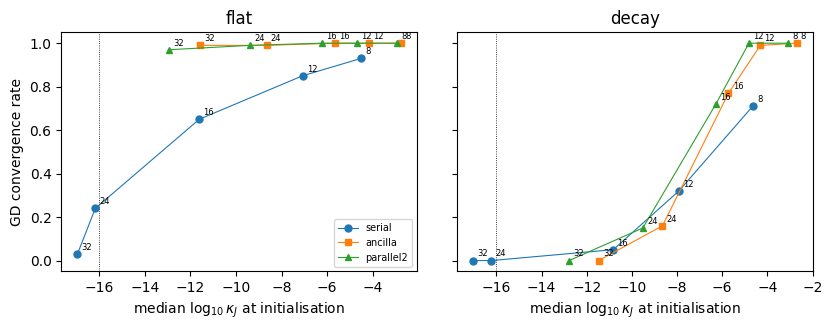


── (3) GD rate (loss <= 1e-06) at the checkpoints [7500, 14500, 27000] and after all 50000 iterations; late_share = share of the converged runs that converged
   after the last of these checkpoints; med_it_1e8 = median step at which the loss reaches 1e-8 (inf: fewer than half of the runs reach it)
                       n  rate_at_7500  rate_at_14500  rate_at_27000  rate_at_end  late_share  med_it_1e8
family E  arm                                                                                            
decay  8  ancilla    100          0.94           0.97           1.00         1.00        0.00      2342.0
          parallel2  100          0.91           0.95           0.99         1.00        0.01      2529.5
          serial     100          0.26           0.40           0.52         0.71        0.27     22051.5
       12 ancilla    100          0.46           0.78           0.92         0.99        0.07      9510.0
          parallel2  100          0.41           0.75           

In [9]:
# ── Cell 5b: conditioning and outcome — strict ordering, initial conditioning, iteration budget ─────────────────
# From runs_gd.csv and kappa.csv only; nothing is run. Replaces the reading of G3 above, whose "at or before" counts
# runs with kappa_J above the threshold at initialisation and runs in which both events fall in one checkpoint interval.
#  (1) order of two events per run: kappa_J first above thr (at a checkpoint) and loss first <= 1e-4 (exact iteration):
#        kappa_at_init  reached, kappa_J above thr at iteration 0                      (uninformative)
#        kappa_first    reached, kappa_J above thr at a checkpoint before the loss iteration
#        unresolved     reached, both events in the same checkpoint interval
#        loss_first     reached, kappa_J still <= thr at the first checkpoint after the loss iteration, above it later
#        loss_only      reached, kappa_J never above thr
#        kappa_only     not reached, kappa_J above thr at some checkpoint;   neither: not reached, never above thr
#      kappa_J is known at the checkpoints only; an excursion between two checkpoints is not seen. Order is not cause.
#  (2) initial conditioning against outcome: per configuration (median log10 kappa_J at iteration 0, GD rate); pairs of
#      configurations of different architectures with matched initial conditioning (medians within MATCH decades);
#      within a configuration, AUC of initial kappa_J for convergence (0.5 = no information), if >= 5 runs of each kind.
#  (3) iteration budget: GD rate at three checkpoints and at the end; share of the converged runs that converged after the
#      last of these checkpoints (a large share means the budget, not the landscape, limits the rate); median step to 1e-8.
G, KP = pd.read_csv(PG), pd.read_csv(PK); MATCH = 0.5
CATS = ['kappa_at_init', 'kappa_first', 'unresolved', 'loss_first', 'loss_only', 'kappa_only', 'neither']; rows = []
for thr in (1e-2, 1e-3, 1e-4):
    for (fam, E, arm), k in KP.groupby(['family', 'E', 'arm']):
        hit = G[(G.family == fam) & (G.E == E) & (G.arm == arm)].set_index('run').it_1e4; n = dict.fromkeys(CATS, 0); lead = []
        for run, h in k.groupby('run'):
            h = h.sort_values('iter'); up = h[h.log_kJ > np.log10(thr)].iter; ki = float(up.min()) if len(up) else np.inf
            li = float(hit[run]) if hit[run] >= 0 else np.inf
            if not np.isfinite(li): n['kappa_only' if np.isfinite(ki) else 'neither'] += 1
            elif ki == 0: n['kappa_at_init'] += 1
            elif ki < li: n['kappa_first'] += 1; lead.append(np.log10(li / ki))
            elif not np.isfinite(ki): n['loss_only'] += 1
            else:
                after = h[h.iter >= li].iter; cstar = float(after.min()) if len(after) else np.inf
                n['unresolved' if ki <= cstar else 'loss_first'] += 1
        rows.append(dict(thr=thr, family=fam, E=E, arm=arm, **n, med_log10_lead=float(np.median(lead)) if lead else np.nan))
G3S = pd.DataFrame(rows); G3S.to_csv(OUT / 'g3_ordering_strict.csv', index=False)
P3 = G3S.groupby(['thr', 'arm'])[CATS].sum(); inf_ = P3[['kappa_first', 'unresolved', 'loss_first', 'loss_only']].sum(axis=1)
ever = P3[['kappa_at_init', 'kappa_first', 'unresolved', 'loss_first']].sum(axis=1)
P3 = P3.assign(informative=inf_, frac_kappa_first=P3.kappa_first / inf_.where(inf_ > 0), frac_unresolved=P3.unresolved / inf_.where(inf_ > 0),
               frac_loss_first=(P3.loss_first + P3.loss_only) / inf_.where(inf_ > 0),
               reach_if_kappa=ever / (ever + P3.kappa_only).where(ever + P3.kappa_only > 0),
               reach_if_no_kappa=P3.loss_only / (P3.loss_only + P3.neither).where(P3.loss_only + P3.neither > 0))
P3.reset_index().to_csv(OUT / 'g3_ordering_strict_pooled.csv', index=False)
print('── (1) order of "kappa_J above thr" and "loss <= 1e-4", pooled over configurations (counts of runs)'); print(P3[CATS])
print('\n   informative = reached, kappa_J not above thr at initialisation; reach_if_(no_)kappa = share of runs reaching 1e-4 among runs with (without) kappa_J above thr at some checkpoint')
print(P3[['informative', 'frac_kappa_first', 'frac_unresolved', 'frac_loss_first', 'reach_if_kappa', 'reach_if_no_kappa']].round(2))

K0 = KP[KP.iter == 0].merge(G[['arm', 'family', 'E', 'run', 'final_loss']], on=['arm', 'family', 'E', 'run']); K0['conv'] = K0.final_loss <= EPS
rows, auc = [], []
for (fam, E, arm), d in K0.groupby(['family', 'E', 'arm']):
    rows.append(dict(family=fam, E=E, arm=arm, med_log_k0=float(d.log_kJ.median()), k=int(d.conv.sum()), n=len(d), rate=float(d.conv.mean())))
    a, b = d[d.conv].log_kJ.values, d[~d.conv].log_kJ.values
    if len(a) >= 5 and len(b) >= 5:
        u = lambda a, b: float(((a[:, None] > b[None, :]) + 0.5 * (a[:, None] == b[None, :])).mean()); rng = np.random.default_rng(0)
        bs = [u(rng.choice(a, len(a)), rng.choice(b, len(b))) for _ in range(1000)]
        auc.append(dict(family=fam, E=E, arm=arm, n_conv=len(a), n_fail=len(b), auc=u(a, b), lo=float(np.quantile(bs, .025)), hi=float(np.quantile(bs, .975))))
C0 = pd.DataFrame(rows); C0.to_csv(OUT / 'kappa_init_vs_rate.csv', index=False)
AU = pd.DataFrame(auc, columns=['family', 'E', 'arm', 'n_conv', 'n_fail', 'auc', 'lo', 'hi']); AU.to_csv(OUT / 'kappa_init_auc.csv', index=False)
rows = []
for fam, d in C0.groupby('family'):
    d = d.reset_index(drop=True)
    for i in range(len(d)):
        for j in range(i + 1, len(d)):
            x, y = d.iloc[i], d.iloc[j]
            if x.arm != y.arm and abs(x.med_log_k0 - y.med_log_k0) <= MATCH:
                if (y.arm == 'serial') or (x.arm != 'serial' and x.arm > y.arm): x, y = y, x          # serial first, else alphabetical
                dd, lo, hi = newcombe(int(y.k), int(y.n), int(x.k), int(x.n))
                rows.append(dict(family=fam, arm_1=x.arm, E_1=int(x.E), log_k0_1=x.med_log_k0, rate_1=x.rate, arm_2=y.arm, E_2=int(y.E),
                                 log_k0_2=y.med_log_k0, rate_2=y.rate, diff_2_minus_1=dd, lo=lo, hi=hi))
MP = pd.DataFrame(rows, columns=['family', 'arm_1', 'E_1', 'log_k0_1', 'rate_1', 'arm_2', 'E_2', 'log_k0_2', 'rate_2', 'diff_2_minus_1', 'lo', 'hi'])
MP.to_csv(OUT / 'kappa_init_matched_pairs.csv', index=False)
print('\n── (2) median log10 kappa_J at initialisation | GD convergence rate, per configuration')
print(C0.assign(cell=C0.apply(lambda r: f'{r.med_log_k0:7.2f} | {r.rate:.2f}', axis=1)).pivot_table(index=['family', 'E'], columns='arm', values='cell', aggfunc='first'))
sp = lambda d: float(d.med_log_k0.corr(d.rate, method='spearman')) if len(d) >= 3 else np.nan
print('\n   Spearman correlation of the two across configurations: all architectures ' + ', '.join(f'{f} {sp(d):+.2f}' for f, d in C0.groupby('family'))
      + ' | within architecture ' + ', '.join(f'{a}/{f} {sp(d):+.2f}' for (a, f), d in C0.groupby(['arm', 'family'])))
print(f'\n   configurations of different architectures with matched initial conditioning (medians within {MATCH} decades); diff = rate_2 − rate_1 [Newcombe 95%]')
print(MP.round(2).to_string(index=False) if len(MP) else '   none')
print('\n   within a configuration: AUC of initial kappa_J for convergence [95% bootstrap] (needs >= 5 converged and >= 5 failed runs)')
print(AU.round(2).to_string(index=False) if len(AU) else '   none')
fig, axs = plt.subplots(1, len(FAMILIES), figsize=(4.2 * len(FAMILIES), 3.4), sharey=True, squeeze=False)
for ax, fam in zip(axs[0], FAMILIES):
    for arm, mk in zip(ARM_LIST, 'os^'):
        d = C0[(C0.family == fam) & (C0.arm == arm)].sort_values('E'); ax.plot(d.med_log_k0, d.rate, mk + '-', label=arm, ms=5, lw=0.8)
        for _, r in d.iterrows(): ax.annotate(str(int(r.E)), (r.med_log_k0, r.rate), fontsize=6, xytext=(3, 3), textcoords='offset points')
    ax.set_title(fam); ax.set_xlabel(r'median $\log_{10}\kappa_J$ at initialisation'); ax.axvline(-16, ls=':', c='k', lw=0.6)
axs[0, 0].set_ylabel('GD convergence rate'); axs[0, 0].legend(fontsize=7); fig.tight_layout(); fig.savefig(OUT / 'fig_kappa_init_vs_rate.pdf'); plt.show()

rows = []; LC = KP.pivot_table(index=['family', 'E', 'arm', 'run'], columns='iter', values='loss')       # loss at the checkpoints (monotone under GD)
CB = [c for c in (7500, 14500, 27000) if c in LC.columns] or sorted(LC.columns)[1:-1][-3:]
for (fam, E, arm), g in G.groupby(['family', 'E', 'arm']):
    lc, it, k = LC.loc[(fam, E, arm)], g.it_1e8.values, int((g.final_loss <= EPS).sum())
    rows.append(dict(family=fam, E=E, arm=arm, n=len(g), **{f'rate_at_{c}': float((lc[c] <= EPS).mean()) for c in CB}, rate_at_end=k / len(g),
                     late_share=float(1 - (lc[CB[-1]] <= EPS).sum() / k) if k and CB else np.nan,
                     med_it_1e8=float(np.median(np.where(it >= 0, it, np.inf)))))
BG = pd.DataFrame(rows); BG.to_csv(OUT / 'gd_budget_curve.csv', index=False)
print(f'\n── (3) GD rate (loss <= {EPS:g}) at the checkpoints {CB} and after all {GD_ITERS} iterations; late_share = share of the converged runs that converged')
print(f'   after the last of these checkpoints; med_it_1e8 = median step at which the loss reaches 1e-8 (inf: fewer than half of the runs reach it)')
print(BG.set_index(['family', 'E', 'arm']).round(2))
